# Movement feature EDA vs outlier labels

Uses `AnomalyPointDataset` (which wraps `select_step_starts()` + `compute_movement_features()` from `trajectories.py`,
same infrastructure as iSSF) to get step-level movement features, then compares distributions against outlier labels.

In [1]:
from __future__ import annotations
from pathlib import Path
import sys
import subprocess
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from movebench import Study
from movebench.trajectories import INDIVIDUAL_COL, LAT_COL, LON_COL, TIME_COL, SET_COL, POINT_ID_COL

## Configuration

In [35]:
STUDY_ID = "Hays_bd9f2614_raw_merged_Eretmochelys_imbricata"
LAYER_CONFIG = "../configs/layers_all.yaml"


movebank_csv = Path(f'/archive/vision/beery/movebench/cleaned_csvs_v1/{STUDY_ID}.csv')#Path( '/archive/vision/beery/movebench/studies_10ind',STUDY_ID,'trajectories.csv')
#Path("/data/vision/beery/scratch/shir/codes/atlastools/atlastools-zenodo/data/bat_data_movebank.csv")  # <-- set this if you want to run ingestion
INGEST_FORCE = False  # set True to overwrite an existing study dir
REPO_ROOT = Path("/data/vision/beery/scratch/shir/codes/movebench/")  
# Step selection — same defaults as extract_point_features / iSSF pipeline
STEP_MULTIPLIER = np.inf
STEP_Q          = 1#0.95
GAP_Q           = 1#0.999

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# --- Download/feature extraction defaults (match example_turtles.ipynb) ---
SAMPLER_RANDOM_SEED = 0
BOUNDS_BUFFER_DEG = 0.01
SETUP_WORKERS = 16


## Optional setup: Download point values (needed for env features)

For `anomaly_dataset`:
- `download_point_values` is needed only when `include_env=True`.
- `extract_point_features` is **not** required. It belongs to the iSSF/SSF raster-chip pipeline and requires `download_rasters` outputs.


In [36]:

try:
    existing = Study(STUDY_ID).study_dir
    print(f"Study already exists: {existing}")
except FileNotFoundError:
    print("Study not found; ingestion can create it.")

    if movebank_csv.exists():
        cmd = [
            sys.executable,
            str(REPO_ROOT / "scripts" / "ingest.py"),
            str(movebank_csv),
            "--study-id",
            STUDY_ID,
        ]
        if INGEST_FORCE:
            cmd.append("--force")
        print("Running:", " ".join(cmd))
        subprocess.run(cmd, check=True)
    else:
        print(f"Skipping ingest (CSV not found): {movebank_csv}")

study = Study(STUDY_ID)
study.study_dir


Study not found; ingestion can create it.
Running: /data/vision/beery/scratch/shir/micromamba/envs/movebench/bin/python /data/vision/beery/scratch/shir/codes/movebench/scripts/ingest.py /archive/vision/beery/movebench/cleaned_csvs_v1/Hays_bd9f2614_raw_merged_Eretmochelys_imbricata.csv --study-id Hays_bd9f2614_raw_merged_Eretmochelys_imbricata
csv_path:   /archive/vision/beery/movebench/cleaned_csvs_v1/Hays_bd9f2614_raw_merged_Eretmochelys_imbricata.csv
study_id:   Hays_bd9f2614_raw_merged_Eretmochelys_imbricata
study_dir:  /archive/vision/beery/movebench/point_based_downloads/studies_10ind/Hays_bd9f2614_raw_merged_Eretmochelys_imbricata
subsample:  max_individuals=10 max_points=100000 random_seed=0 stop=all_individuals
n_points:   24017 (from 24017)
individuals:6 (from 6)
split:      train=11983 test=12034


PosixPath('/archive/vision/beery/movebench/point_based_downloads/studies_10ind/Hays_bd9f2614_raw_merged_Eretmochelys_imbricata')

NameError: name 'ee' is not defined

In [37]:
import ee
ee.Initialize(project="movebench")
print(ee.Number(1).getInfo())
study = Study(STUDY_ID)

point_values_report = study.download_point_values(
    config=LAYER_CONFIG,
    splits=["train", "test"],
    n_workers=SETUP_WORKERS,
    skip_existing=True,
)
point_values_report


1


Sampling point values: 100%|██████████| 13602/13602 [04:39<00:00, 48.59batch/s]


{'config_hash': 'd48ca522da00e99e',
 'parquet_path': '/archive/vision/beery/movebench/point_based_downloads/studies_10ind/Hays_bd9f2614_raw_merged_Eretmochelys_imbricata/point_values/d48ca522da00e99e/values.parquet',
 'n_points': 24017,
 'n_downloaded': 24017,
 'n_existing': 0,
 'n_failed': 0,
 'failures': []}

In [6]:
# Optional: iSSF/SSF point-feature extraction (requires raster chips from download_rasters).
# Not needed for study.anomaly_dataset(...), which uses point_values + trajectories directly.
RUN_ISSF_EXTRACTION = False

if RUN_ISSF_EXTRACTION:
    # Requires: study.download_rasters(...) already completed for this config/splits.
    extract_report = study.extract_point_features(
        config=LAYER_CONFIG,
        splits=["train", "test"],
        parametric=True,
        num_candidates=0,
        random_seed=SAMPLER_RANDOM_SEED,
        n_workers=SETUP_WORKERS,
        skip_existing=True,
        step_multiplier=STEP_MULTIPLIER,
        step_q=STEP_Q,
        gap_q=GAP_Q,
        bounds_buffer_deg=BOUNDS_BUFFER_DEG,
    )
    sampler_hash = extract_report["sampler_hash"]
    print("sampler_hash:", sampler_hash)
    extract_report
else:
    print("Skipping extract_point_features (not required for anomaly_dataset).")


Skipping extract_point_features (not required for anomaly_dataset).


## Create dataset (movement features only, unnormalized)

`AnomalyPointDataset` runs `select_step_starts()` + `compute_movement_features()` internally.
We use all splits together and skip env features — we only want to inspect movement.

In [11]:
study = Study(STUDY_ID)

ds = study.anomaly_dataset(
    split=None,          # all splits
    config=LAYER_CONFIG,
    include_env=False,
    include_movement=True,
    include_outgoing_movement=True,
    normalize=False,        # keep raw physical units
    step_multiplier=STEP_MULTIPLIER,
    step_q=STEP_Q,
    gap_q=GAP_Q,
)


print("n_steps     :", len(ds))

print("features    :", ds.feature_names)
df = ds.to_dataframe()   # point_id_start + movement feature columns
df["any_outlier"] = ds.labels(any_outlier=True)
df["individual"]  = ds.individual_ids()
df.head()

/data/vision/beery/scratch/shir/codes/movebench/movebench/datasets/anomaly.py:240: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(trajectories_path)
/data/vision/beery/scratch/shir/codes/movebench/movebench/trajectories.py:109: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid_step_next = df["valid_step"].shift(-1).fillna(False).astype(bool)
/data/vision/beery/scratch/shir/codes/movebench/movebench/datasets/anomaly.py:294: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  self._meta_df = pd.read_csv(trajectories_path).set_index(POINT_ID_COL)


n_steps     : 75179
features    : ['step_length_m', 'step_dt_s', 'speed_m_s', 'turn_angle_rad', 'step_length_m_next', 'step_dt_s_next', 'speed_m_s_next', 'turn_angle_rad_next']


/data/vision/beery/scratch/shir/codes/movebench/movebench/datasets/anomaly.py:343: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pd.DataFrame({c: meta[c].fillna(False).astype(bool) for c in outlier_cols})
/data/vision/beery/scratch/shir/codes/movebench/movebench/datasets/anomaly.py:343: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pd.DataFrame({c: meta[c].fillna(False).astype(bool) for c in outlier_cols})
/data/vision/beery/scratch/shir/codes/movebench/movebench/datasets/anomaly.py:343: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, 

,point_id_start,step_length_m,step_dt_s,speed_m_s,turn_angle_rad,step_length_m_next,step_dt_s_next,speed_m_s_next,turn_angle_rad_next,any_outlier,individual
0,1,6.900665,3601.0,0.001916,NaN,3.675212,22815.0,0.000161,-3.110961,False,Adi + / DER AU893 (eobs 3029)
1,2,3.675212,22815.0,0.000161,-3.110961,6.250573,3583.0,0.001745,2.059944,False,Adi + / DER AU893 (eobs 3029)
2,3,6.250573,3583.0,0.001745,2.059944,5.448534,3600.0,0.001513,-2.894728,False,Adi + / DER AU893 (eobs 3029)
3,4,5.448534,3600.0,0.001513,-2.894728,4.941478,3601.0,0.001372,-1.097061,False,Adi + / DER AU893 (eobs 3029)
4,5,4.941478,3601.0,0.001372,-1.097061,6.051189,3600.0,0.001681,2.152441,False,Adi + / DER AU893 (eobs 3029)


In [12]:
ds.feature_names

['step_length_m',
 'step_dt_s',
 'speed_m_s',
 'turn_angle_rad',
 'step_length_m_next',
 'step_dt_s_next',
 'speed_m_s_next',
 'turn_angle_rad_next']

In [14]:
traj_df = pd.read_csv(study.trajectories_path)
traj_df["timestamp"] = pd.to_datetime(traj_df["timestamp"], format='%Y-%m-%d %H:%M:%S', errors="coerce")
traj_df = traj_df.dropna(subset=["timestamp"])  # drop unparseable timestamps
# merge traj_df and df on point_id and point_id_start respectively:
merged_df= pd.merge(traj_df,df,left_on='point_id',right_on='point_id_start')

/tmp/ipykernel_78948/960150404.py:1: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  traj_df = pd.read_csv(study.trajectories_path)


In [15]:
merged_df[merged_df['speed_m_s']==0][['point_id',LAT_COL,LON_COL,TIME_COL,'ground-speed','speed_m_s',
                                      'speed_m_s_next','step_dt_s','algorithm-marked-outlier',
                                      'manually-marked-outlier','any_outlier','individual']].describe()

,point_id,location-lat,location-long,timestamp,ground-speed,speed_m_s,speed_m_s_next,step_dt_s
count,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# plan = study.layer_plan(LAYER_CONFIG)
# pv_path = study.study_dir / "point_values" / plan.config_hash / "values.parquet"
# pv = pd.read_parquet(pv_path).set_index("point_id")

# ds = study.anomaly_dataset(
#     split=None, config=LAYER_CONFIG,
#     include_env=True, include_movement=False,
#     normalize=False,
#     step_multiplier=STEP_MULTIPLIER, step_q=STEP_Q, gap_q=GAP_Q,
# )
# dd = ds.to_dataframe()[["point_id_start", "era5.mean_sea_level_pressure"]].set_index("point_id_start")

# cmp = dd.join(pv[["era5.mean_sea_level_pressure"]], how="left", rsuffix="_pv")
# cmp["abs_diff"] = (cmp["era5.mean_sea_level_pressure"] - cmp["era5.mean_sea_level_pressure_pv"]).abs()
# print(cmp["abs_diff"].describe())
# print("max diff:", cmp["abs_diff"].max())

/data/vision/beery/scratch/shir/codes/movebench/movebench/datasets/anomaly.py:240: DtypeWarning: Columns (15,18) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(trajectories_path)
/data/vision/beery/scratch/shir/codes/movebench/movebench/trajectories.py:109: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid_step_next = df["valid_step"].shift(-1).fillna(False).astype(bool)


count    124830.0
mean          0.0
std           0.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max           0.0
Name: abs_diff, dtype: float64
max diff: 0.0


/data/vision/beery/scratch/shir/codes/movebench/movebench/datasets/anomaly.py:294: DtypeWarning: Columns (15,18) have mixed types. Specify dtype option on import or set low_memory=False.
  self._meta_df = pd.read_csv(trajectories_path).set_index(POINT_ID_COL)


In [38]:
band_id

NameError: name 'band_id' is not defined

In [39]:

era5_by_time = {k:{} for k in df.columns if k.startswith("era5.")}
pids_to_timestamps = dict(zip(ds.point_id_start, ds.timestamp_ns))
for row_id in range(1000,2400):
# Pick a point to visualize.
    row = merged_df[merged_df["point_id"] == row_id]
    point_id = int(row["point_id"])
    timestamp = row["timestamp"].values[0]
    for band_id in era5_by_time.keys():
        values = row[band_id].values[0]
        era5_by_time[band_id][timestamp] = values
# plot ERA5 by time:
for band_id, values_by_time in era5_by_time.items():
    times = sorted(values_by_time.keys())
    values = np.array([values_by_time[t] for t in times])
    plt.figure(figsize=(10, 4))
    if  band_id=='era5.mean_sea_level_pressure':
        values=values/100.0
    plt.plot(times, values)
    plt.title(f"ERA5 {band_id} over time")
    plt.xlabel("Time")
    plt.ylabel(band_id)
    plt.xticks(rotation=45)
    plt.ticklabel_format(axis="y", style="plain", useOffset=False)
    plt.tight_layout()
    plt.grid()
    plt.show()

/tmp/ipykernel_2230687/1324895714.py:6: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  point_id = int(row["point_id"])


## Outlier label coverage

In [28]:
study.trajectories_path

PosixPath('/archive/vision/beery/movebench/point_based_downloads/studies_10ind/Carter_Red_Fox/trajectories.csv')

In [16]:
# Pull per-column outlier flags aligned to step starts
raw = pd.read_csv(study.trajectories_path)
outlier_cols = [c for c in raw.columns if "outlier" in c.lower()]
print("outlier cols:", outlier_cols)

meta = raw.set_index(POINT_ID_COL)[outlier_cols]
for col in outlier_cols:
    df[col] = meta.reindex(df["point_id_start"])[col].fillna(False).astype(bool).values

for col in outlier_cols:
    print(f"  {col}: {df[col].sum()} / {len(df)} steps ({df[col].mean():.1%})")

outlier cols: ['algorithm-marked-outlier', 'import-marked-outlier', 'manually-marked-outlier']
  algorithm-marked-outlier: 2238 / 75179 steps (3.0%)
  import-marked-outlier: 0 / 75179 steps (0.0%)
  manually-marked-outlier: 6441 / 75179 steps (8.6%)


/tmp/ipykernel_78948/2624171212.py:2: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.read_csv(study.trajectories_path)
/tmp/ipykernel_78948/2624171212.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = meta.reindex(df["point_id_start"])[col].fillna(False).astype(bool).values
/tmp/ipykernel_78948/2624171212.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = meta.reindex(df["point_id_start"])[col].fillna(False).astype(bool).values
/tmp/ipykernel_78948/2624171212.py:8: Fut

## Movement feature distributions vs outlier label

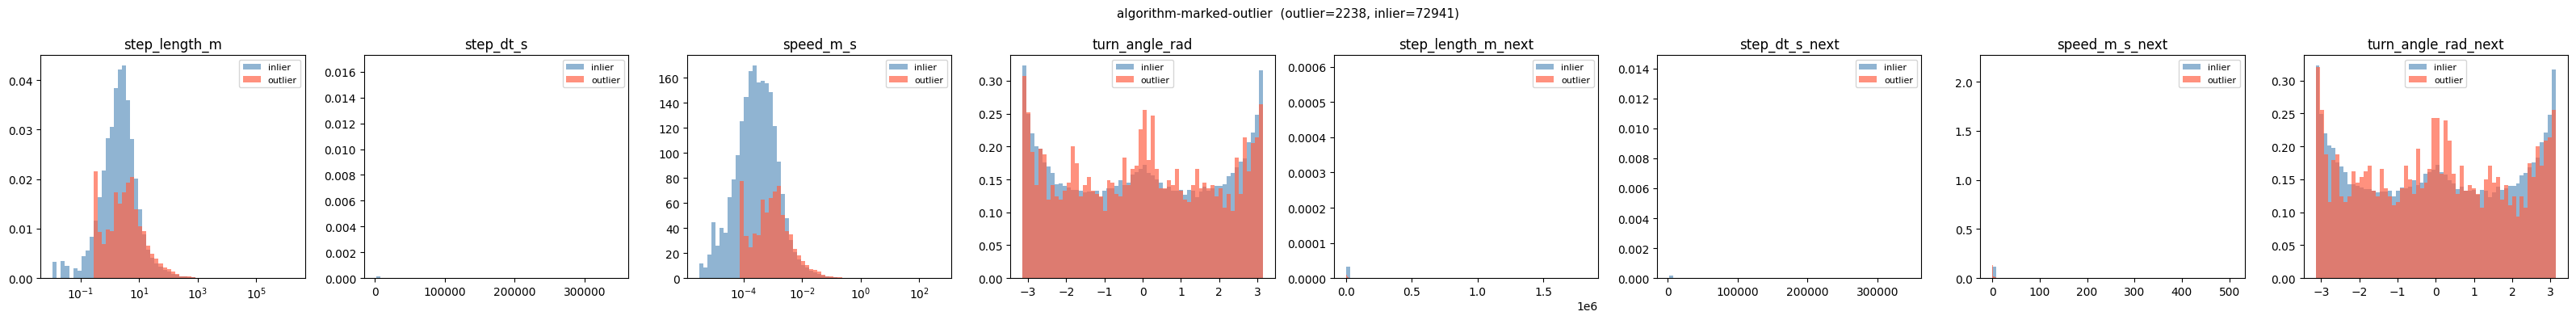

import-marked-outlier: no positive labels


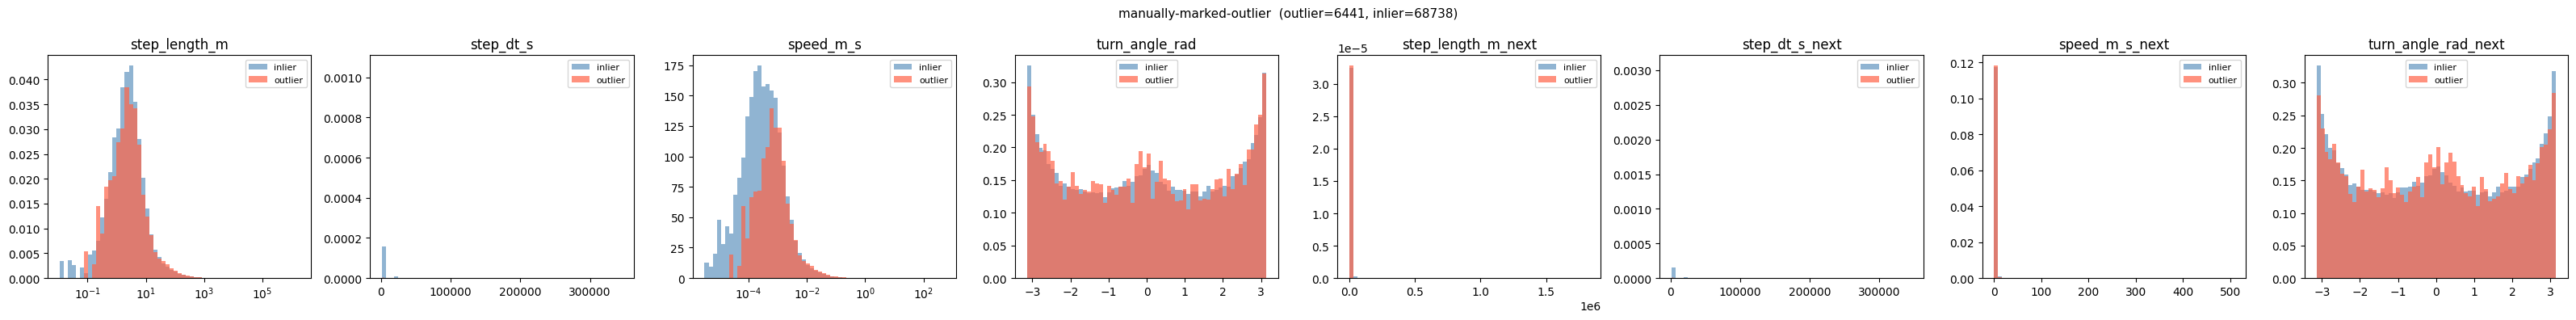

In [17]:
mov_feats = ds.feature_names  # ["step_length_m", "step_dt_s", "speed_m_s", "turn_angle_rad"]

for col in outlier_cols:
    n_out = df[col].sum()
    n_in  = (~df[col]).sum()
    if n_out == 0:
        print(f"{col}: no positive labels")
        continue

    fig, axes = plt.subplots(1, len(mov_feats), figsize=(4 * len(mov_feats), 4))
    fig.suptitle(f"{col}  (outlier={n_out}, inlier={n_in})", fontsize=11)

    for ax, feat in zip(axes, mov_feats):
        v_in  = df.loc[~df[col], feat].dropna()
        v_out = df.loc[ df[col], feat].dropna()
        log   = feat in ("step_length_m", "speed_m_s")
        all_v = pd.concat([v_in, v_out])
        if log and (all_v > 0).any():
            lo = max(all_v[all_v > 0].min(), 1e-6)
            bins = np.logspace(np.log10(lo), np.log10(all_v.max()), 60)
        else:
            bins = 60

        ax.hist(v_in,  bins=bins, alpha=0.6, color="steelblue", label="inlier",  density=True)
        ax.hist(v_out, bins=bins, alpha=0.7, color="tomato",    label="outlier", density=True)
        if log:
            ax.set_xscale("log")
        ax.set_title(feat)
        ax.legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{STUDY_ID}_{col.replace('/', '_')}_movement.png", dpi=120, bbox_inches="tight")
    plt.show()

## Speed percentile table by outlier label

In [18]:
qs = [0.5, 0.75, 0.9, 0.95, 0.99, 1.0]
rows = []
for col in outlier_cols:
    for group, mask in [("inlier", ~df[col]), ("outlier", df[col])]:
        spd = df.loc[mask, "speed_m_s"].dropna()
        row = {"outlier_col": col, "group": group, "n": len(spd)}
        for q in qs:
            row[f"p{int(q*100)}"] = np.nanquantile(spd, q) if len(spd) else np.nan
        rows.append(row)

pd.DataFrame(rows).set_index(["outlier_col", "group"]).round(2)

n   p50   p75   p90   p95   p99    p100
outlier_col              group                                               
algorithm-marked-outlier inlier   72941  0.01  0.11  0.77  1.87  7.01  507.15
                         outlier   2238  0.03  0.16  1.50  3.95  9.22   22.60
import-marked-outlier    inlier   75179  0.01  0.11  0.78  1.92  7.11  507.15
                         outlier      0   NaN   NaN   NaN   NaN   NaN     NaN
manually-marked-outlier  inlier   68738  0.01  0.11  0.79  2.00  7.27  507.15
                         outlier   6441  0.02  0.12  0.70  1.32  4.91  507.09

## Spatial map: speed at each step start, outliers marked

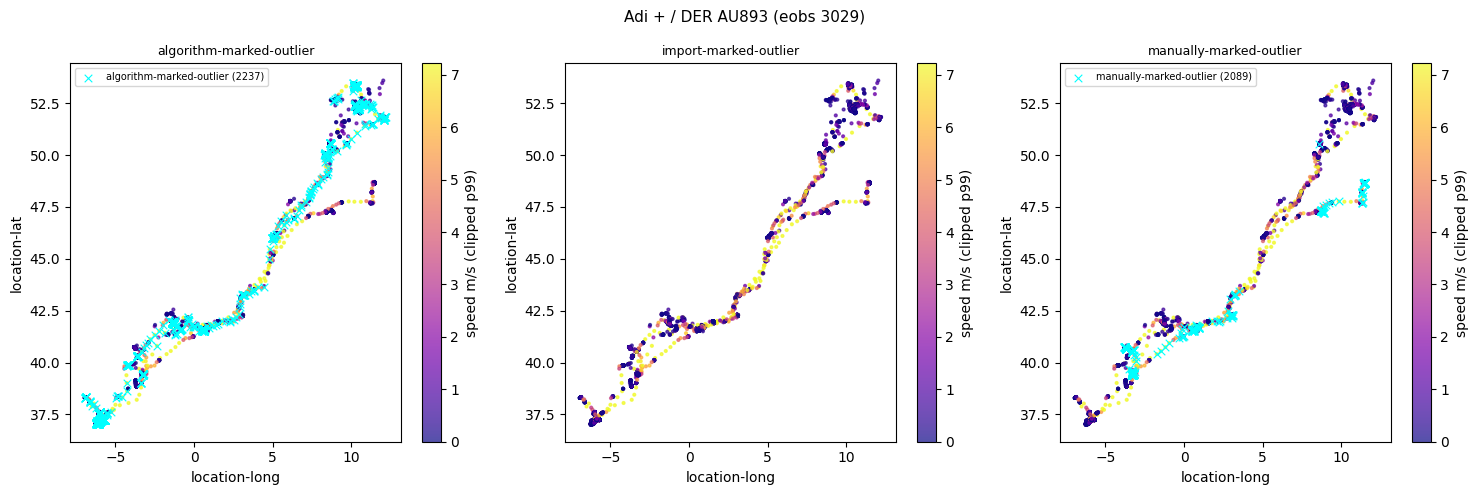

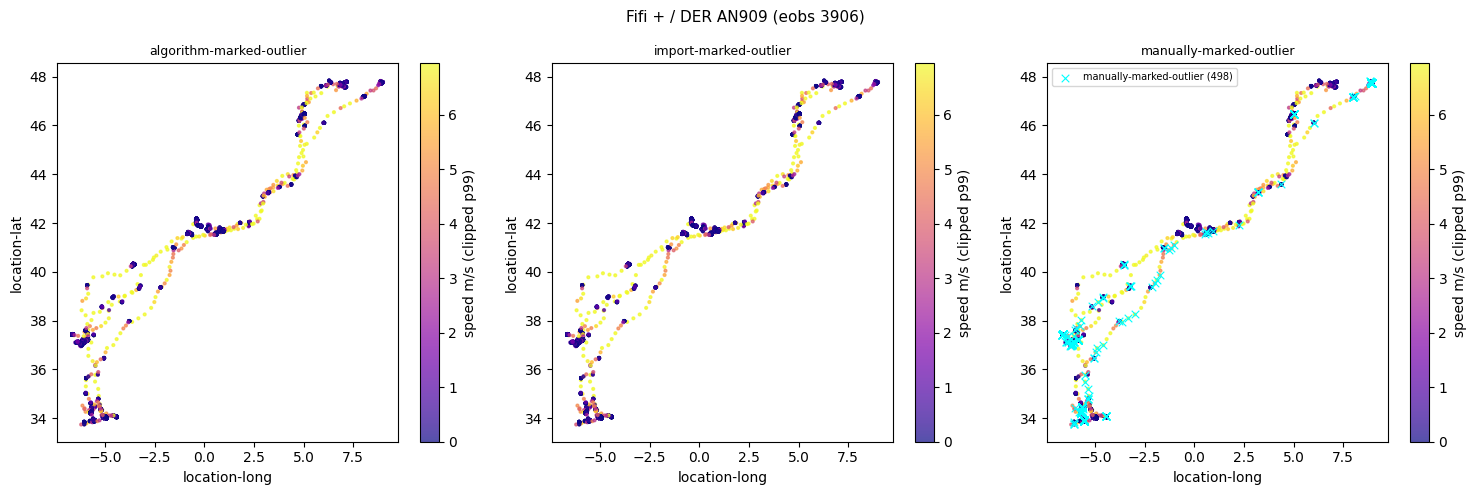

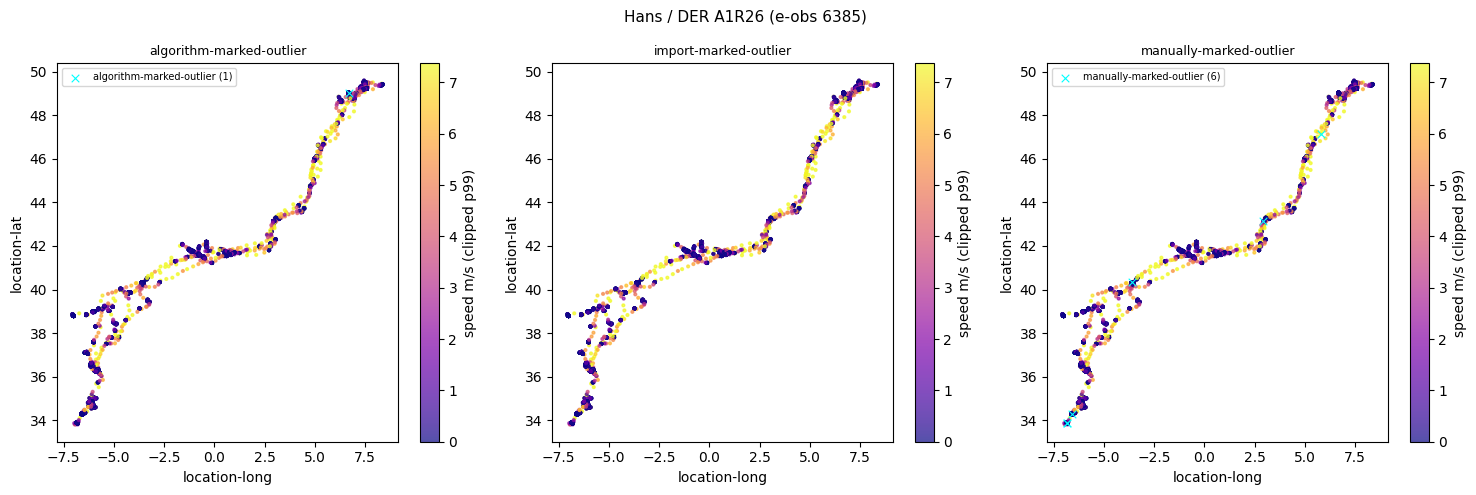

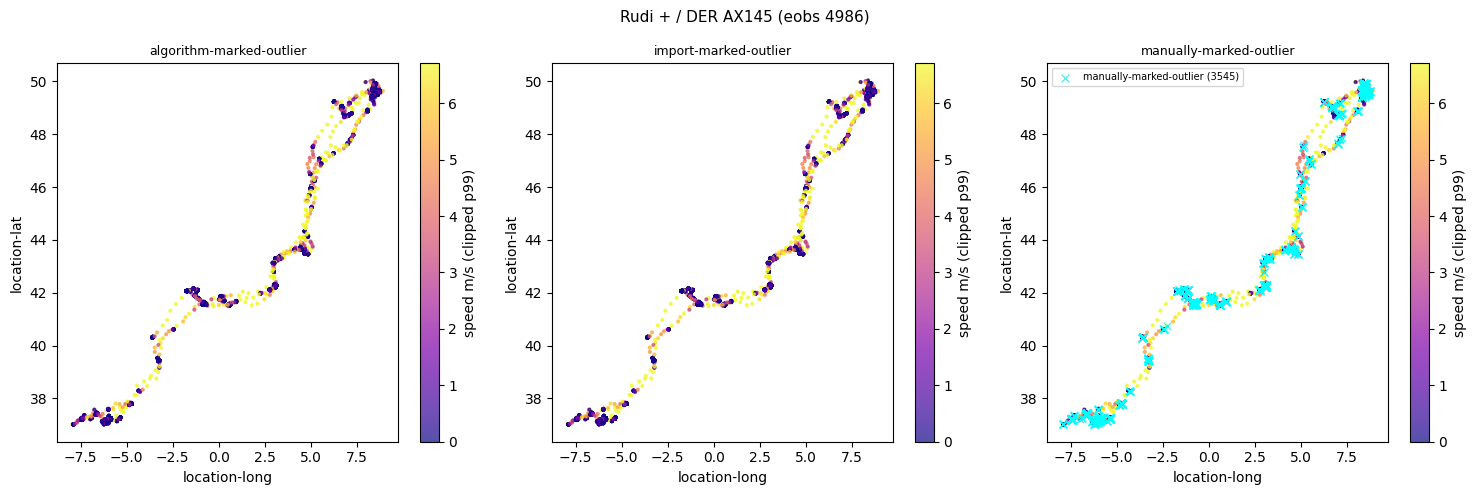

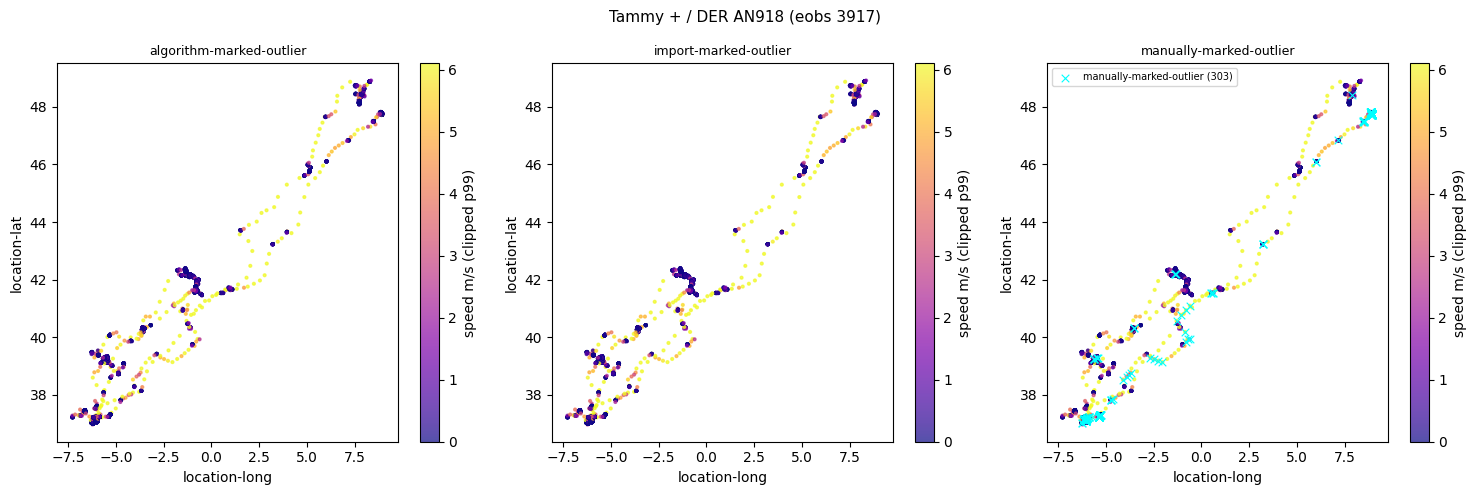

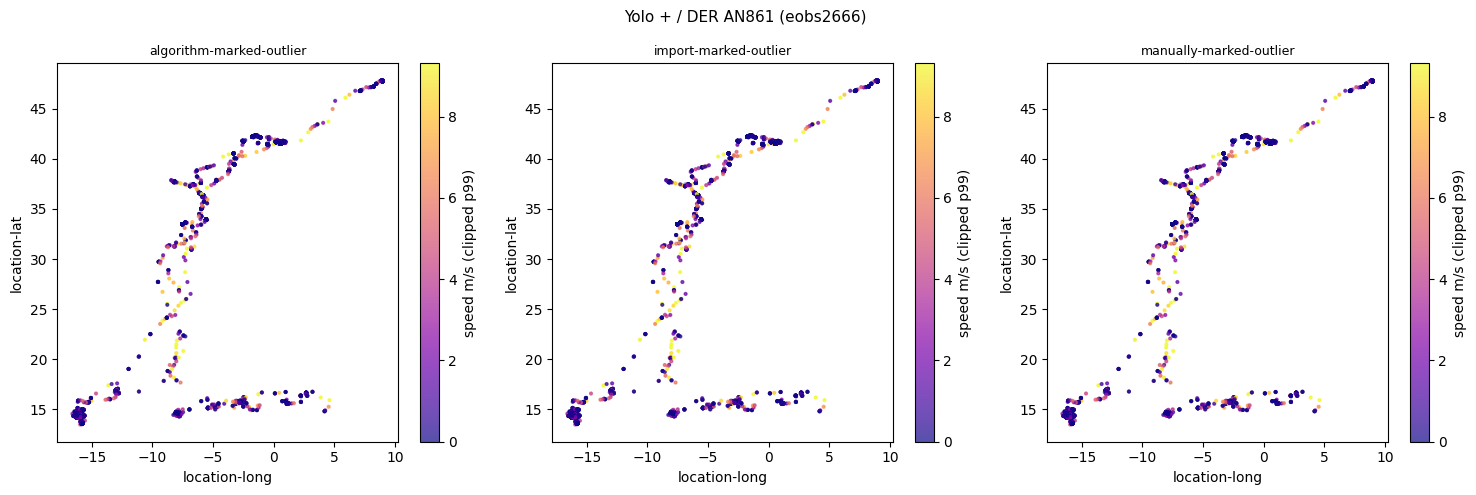

In [19]:
traj = raw.set_index(POINT_ID_COL)[[LON_COL, LAT_COL]]
coords = traj.reindex(df["point_id_start"])
df[LON_COL] = coords[LON_COL].values
df[LAT_COL] = coords[LAT_COL].values

primary_col = outlier_cols[0] if outlier_cols else None

for ind in df["individual"].unique():
    s = df[df["individual"] == ind].dropna(subset=["speed_m_s", LON_COL, LAT_COL])
    if len(s) == 0:
        
        continue

    fig, axes = plt.subplots(1, len(outlier_cols), figsize=(5 * len(outlier_cols), 5))
    if len(outlier_cols) == 1:
        axes = [axes]
    fig.suptitle(str(ind), fontsize=11)

    for ax, col in zip(axes, outlier_cols):
        vmax = np.nanpercentile(s["speed_m_s"], 99)
        sc = ax.scatter(s[LON_COL], s[LAT_COL], c=s["speed_m_s"].clip(upper=vmax),
                        cmap="plasma", s=4, alpha=0.7, vmin=0, vmax=vmax)
        label = s[col]
        if label.sum() > 0:
            ax.scatter(s.loc[label, LON_COL], s.loc[label, LAT_COL],
                       c="cyan", s=30, marker="x", lw=0.8,
                       label=f"{col} ({label.sum()})", zorder=5)
            ax.legend(fontsize=7)
        plt.colorbar(sc, ax=ax, label="speed m/s (clipped p99)")
        ax.set_title(col, fontsize=9)
        ax.set_xlabel(LON_COL); ax.set_ylabel(LAT_COL)

    plt.tight_layout()
    #plt.savefig(FIG_DIR / f"{STUDY_ID}_{ind}_speed_map.png", dpi=120, bbox_inches="tight")
    plt.show()

In [ ]:
speed_outliers=df[df['speed-outlier']].sort_values("speed_m_s", ascending=True)
speed_outliers['max_speed'] = speed_outliers.apply(lambda row: max(row['speed_m_s'], row['speed_m_s_next']), axis=1)

In [ ]:
suspect = speed_outliers[speed_outliers['max_speed']<=20]


In [44]:
df

,point_id_start,step_length_m,step_dt_s,speed_m_s,turn_angle_rad,step_length_m_next,step_dt_s_next,speed_m_s_next,turn_angle_rad_next,any_outlier,individual,algorithm-marked-outlier,manually-marked-outlier
0,1,1.945918,30.0,0.064864,NaN,1.050245,1171.0,0.000897,1.847643,False,Flo,False,False
1,2,1.050245,1171.0,0.000897,1.847643,17.150183,1200.0,0.014292,1.539793,False,Flo,False,False
2,3,17.150183,1200.0,0.014292,1.539793,15.431180,1201.0,0.012849,2.988918,False,Flo,False,False
3,4,15.431180,1201.0,0.012849,2.988918,6.572075,1200.0,0.005477,0.307421,False,Flo,False,False
4,5,6.572075,1200.0,0.005477,0.307421,11.891619,1200.0,0.009910,-0.081776,True,Flo,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
21389,21392,551.026611,1204.0,0.457663,0.111250,62.560848,1200.0,0.052134,-0.030649,False,Oli,False,False
21390,21393,62.560848,1200.0,0.052134,-0.030649,29.919746,1203.0,0.024871,-1.456854,False,Oli,False,False
21391,21394,29.919746,1203.0,0.024871,-1.456854,39.868023,1193.0,0.033418,-2.104054,False,Oli,False,False
21392,21395,39.868023,1193.0,0.033418,-2.104054,16.332329,1202.0,0.013588,0.728710,False,Oli,False,False


In [45]:

raw_sorted = raw.sort_values([INDIVIDUAL_COL, TIME_COL]).reset_index(drop=True)
pos_lookup = {pid: i for i, pid in enumerate(raw_sorted[POINT_ID_COL])}

rows = []
for pid in suspect["point_id_start"]:
    pos = pos_lookup[pid]
    prev_row = raw_sorted.iloc[pos - 1] if pos > 0 else None
    next_row = raw_sorted.iloc[pos + 1] if pos < len(raw_sorted) - 1 else None
    rows.append({
        "point_id_start":         pid,
        "speed_m_s":              suspect.loc[suspect["point_id_start"] == pid, "speed_m_s"].values[0],
        "speed_m_s_next":         suspect.loc[suspect["point_id_start"] == pid, "speed_m_s_next"].values[0],
        "prev_point_id":          prev_row[POINT_ID_COL] if prev_row is not None else None,
        "prev_system_outlier":    prev_row["system-outlier"] if prev_row is not None else None,
        "prev_individual":        prev_row[INDIVIDUAL_COL] if prev_row is not None else None,
        "next_point_id":          next_row[POINT_ID_COL] if next_row is not None else None,
        "next_system_outlier":    next_row["system-outlier"] if next_row is not None else None,
        "next_individual":        next_row[INDIVIDUAL_COL] if next_row is not None else None,
    })

pd.DataFrame(rows)

NameError: name 'suspect' is not defined

In [ ]:
def speed_to_neighbor(pid, raw_sorted, pos_lookup, direction="next"):
    pos = pos_lookup[pid]
    row = raw_sorted.iloc[pos]
    step = 1 if direction == "next" else -1
    i = pos + step
    while 0 <= i < len(raw_sorted):
        neighbor = raw_sorted.iloc[i]
        if neighbor[INDIVIDUAL_COL] != row[INDIVIDUAL_COL]:
            return None, None   # hit individual boundary
        if not neighbor["system-outlier"]:
            dt = abs((neighbor[TIME_COL] - row[TIME_COL]).total_seconds())
            dist = _haversine(
                row[LAT_COL], row[LON_COL],
                neighbor[LAT_COL], neighbor[LON_COL],
            )
            speed = dist / dt if dt > 0 else np.nan
            return speed, neighbor[POINT_ID_COL]
        i += step
    return None, None

from movebench.datasets.anomaly import _haversine

raw_sorted = raw.sort_values([INDIVIDUAL_COL, TIME_COL]).reset_index(drop=True)
raw_sorted[TIME_COL] = pd.to_datetime(raw_sorted[TIME_COL])
pos_lookup = {pid: i for i, pid in enumerate(raw_sorted[POINT_ID_COL])}

suspect = df[df["speed-outlier"] & (df["speed_m_s"] < 20) & (df["speed_m_s_next"] < 20)]

rows = []
for pid in suspect["point_id_start"]:
    spd_prev, prev_pid = speed_to_neighbor(pid, raw_sorted, pos_lookup, "prev")
    spd_next, next_pid = speed_to_neighbor(pid, raw_sorted, pos_lookup, "next")
    rows.append({
        "point_id_start":   pid,
        "speed_m_s":        suspect.loc[suspect["point_id_start"] == pid, "speed_m_s"].values[0],
        "speed_m_s_next":   suspect.loc[suspect["point_id_start"] == pid, "speed_m_s_next"].values[0],
        "prev_nonoutlier_pid":   prev_pid,
        "speed_to_prev_non_sys": spd_prev,
        "next_nonoutlier_pid":   next_pid,
        "speed_to_next_non_sys": spd_next,
    })

pd.DataFrame(rows)


In [47]:
df[(df["point_id_start"] <32645)& (df["point_id_start"]>32620)]

,point_id_start,step_length_m,step_dt_s,speed_m_s,turn_angle_rad,step_length_m_next,step_dt_s_next,speed_m_s_next,turn_angle_rad_next,any_outlier,individual,algorithm-marked-outlier,manually-marked-outlier


In [24]:
merged_df.columns

Index(['Unnamed: 0', 'event-id', 'visible', 'timestamp', 'location-long',
       'location-lat', 'algorithm-marked-outlier', 'external-temperature',
       'gps:hdop', 'gps:maximum-signal-strength', 'gps:satellite-count',
       'height-above-msl', 'manually-marked-outlier', 'sensor-type',
       'individual-taxon-canonical-name', 'tag-local-identifier',
       'individual-local-identifier', 'study-name', 'split-time', 'set',
       'point-id', 'point_id', 'point_id_start', 'step_length_m', 'step_dt_s',
       'speed_m_s', 'turn_angle_rad', 'step_length_m_next', 'step_dt_s_next',
       'speed_m_s_next', 'turn_angle_rad_next', 'any_outlier', 'individual',
       'max_speed'],
      dtype='object')

In [26]:
# check if there any points with max speed above the thresh old but not labeled as outliers
merged_df['max_speed'] = merged_df.apply(lambda row: max(row['speed_m_s'], row['speed_m_s_next']), axis=1)
merged_df[(merged_df['max_speed'] > 20) ][['any_outlier','speed_m_s','speed_m_s_next','gps:hdop','gps:satellite-count','gps:maximum-signal-strength']]

,any_outlier,speed_m_s,speed_m_s_next,gps:hdop,gps:satellite-count,gps:maximum-signal-strength
1210,False,0.005877,204.916641,4.7,5,31.0
1211,True,204.916641,103.401337,9.3,3,26.0
1212,True,103.401337,3.037722,5.0,3,39.0
5873,False,0.017400,36.608341,2.2,4,28.0
5874,True,36.608341,36.886639,4.7,4,30.0
5875,False,36.886639,0.001825,2.2,5,30.0
10001,True,0.002050,215.762100,2.1,3,43.0
10002,True,215.762100,0.426414,2.3,3,42.0


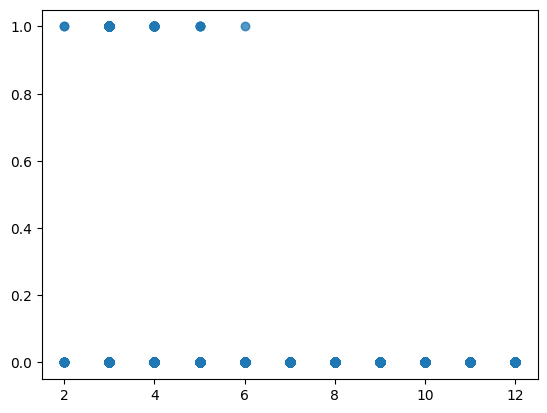

In [ ]:
plt(merged_df['gps:satellite-count'],merged_df['any_outlier'], alpha=0.5)

In [29]:
merged_df.to_csv("/data/vision/beery/scratch/shir/codes/movebench/notebooks/Carter_Red_Fox_merged_df.csv", index=False)




In [13]:
ds.feature_names

['modis_lst.LST_Day_1km',
 'modis_lst.LST_Night_1km',
 'modis_vi.NDVI',
 'modis_vi.EVI',
 'modis_ndsi.NDSI',
 'modis_bai.BAI',
 'era5_land.temperature_2m',
 'era5_land.dewpoint_temperature_2m',
 'era5_land.total_precipitation',
 'era5_land.surface_pressure',
 'era5_land.u_component_of_wind_10m',
 'era5_land.v_component_of_wind_10m',
 'era5_land.surface_solar_radiation_downwards',
 'era5_land.surface_thermal_radiation_downwards',
 'era5_land.surface_net_solar_radiation',
 'era5_land.surface_net_thermal_radiation',
 'era5_land.surface_latent_heat_flux',
 'era5_land.surface_sensible_heat_flux',
 'era5_land.snow_depth',
 'era5.boundary_layer_height',
 'era5.total_cloud_cover',
 'era5.mean_sea_level_pressure',
 'era5_land_daily.temperature_2m',
 'era5_land_daily.dewpoint_temperature_2m',
 'era5_land_daily.total_precipitation_sum',
 'era5_land_daily.surface_pressure',
 'era5_land_daily.u_component_of_wind_10m',
 'era5_land_daily.v_component_of_wind_10m',
 'era5_land_daily.surface_solar_radia

In [44]:
vmaxes = np.nanpercentile(ds._features, 99.95,axis=0)
vmaxes[6]

np.float32(10661.414)

6 ['Adi + / DER AU893 (eobs 3029)' 'Fifi + / DER AN909 (eobs 3906)'
 'Hans / DER A1R26 (e-obs 6385)' 'Rudi + / DER AX145 (eobs 4986)'
 'Tammy + / DER AN918 (eobs 3917)' 'Yolo + / DER AN861 (eobs2666)']


/data/vision/beery/scratch/shir/codes/movebench/movebench/datasets/anomaly.py:343: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pd.DataFrame({c: meta[c].fillna(False).astype(bool) for c in outlier_cols})
/data/vision/beery/scratch/shir/codes/movebench/movebench/datasets/anomaly.py:343: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pd.DataFrame({c: meta[c].fillna(False).astype(bool) for c in outlier_cols})
/data/vision/beery/scratch/shir/codes/movebench/movebench/datasets/anomaly.py:343: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, 

Text(0, 0.5, 'speed_m_s_next')

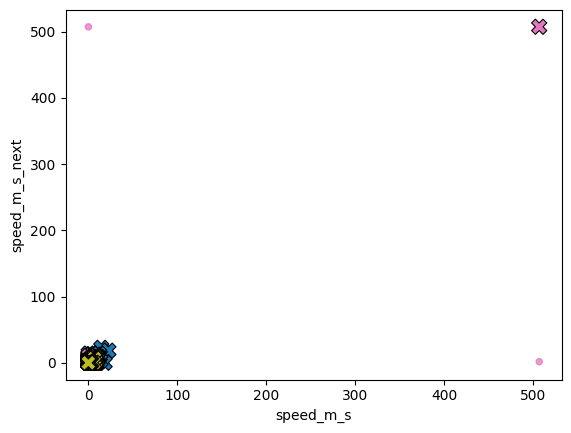

In [23]:
# plot speed_m_s and speed_m_s_next color them by individual id and mark the outliers with a different marker:

individual_ids = np.array([traj_df.loc[traj_df['point_id'] == pid, INDIVIDUAL_COL].values[0] for pid in ds.point_id_start])
unique_individuals = np.unique(individual_ids)
    #map indivdual IDs to integers starting from 0
individual_id_to_int = {ind: i for i, ind in enumerate(unique_individuals)}
    # color these dim reductions by individual ID instead of outlier status, to see if individuals cluster together
unique_individuals = np.unique(individual_ids)
    #map indivdual IDs to integers starting from 0
individual_id_to_int = {ind: i for i, ind in enumerate(unique_individuals)}
individual_ids = np.array([individual_id_to_int[ind] for ind in individual_ids])
n_individuals = len(unique_individuals)
print(n_individuals, unique_individuals)
    # create a color map with n_individuals distinct colors
cmap_individuals = plt.get_cmap('tab20', n_individuals)

outlier_mask = np.asarray(ds.labels(), dtype=bool)
inlier_mask = ~outlier_mask
plt.scatter(ds._features[inlier_mask, 2],#.clip(max=vmaxes[2]), 
            ds._features[inlier_mask, 6],#.clip(max=vmaxes[6]),
                    c=individual_ids[inlier_mask], cmap=cmap_individuals, alpha=0.75, s=20)
if outlier_mask.any():
    plt.scatter(ds._features[outlier_mask, 2],#.clip(max=vmaxes[2]),
                 ds._features[outlier_mask, 6],#.clip(max=vmaxes[6]),
                        c=cmap_individuals(individual_ids[outlier_mask]), marker='X', s=120,
                        edgecolors='k', linewidths=0.8)
plt.xlabel('speed_m_s')
plt.ylabel('speed_m_s_next')

In [24]:
individual_ids

array([0, 0, 0, ..., 3, 3, 3], shape=(124830,))

In [27]:
merged_df.describe()

,Unnamed: 0,event-id,timestamp,location-long_x,location-lat_x,gps:hdop,gps:satellite-count,gps-time-to-fix,gps:vdop,ground-speed,...,step_length_m,step_dt_s,speed_m_s,turn_angle_rad,step_length_m_next,step_dt_s_next,speed_m_s_next,turn_angle_rad_next,location-long_y,location-lat_y
count,124830.000000,1.248300e+05,124830,124830.000000,124830.000000,102040.000000,102040.000000,0.0,102040.000000,124830.000000,...,1.248300e+05,124830.000000,124830.000000,116360.000000,1.248260e+05,124826.000000,124826.000000,116360.000000,124830.000000,124830.000000
mean,175867.690179,1.067419e+10,2019-01-04 09:26:33.365136128,-76.326546,31.919404,1.338754,7.539984,NaN,1.815221,5.410901,...,4.772426e+04,1788.445068,33.964584,-0.007994,4.765510e+04,1788.352539,33.955788,-0.007994,-76.326546,31.919404
min,1.000000,1.032949e+09,2015-07-16 15:18:12,-117.044330,-41.448170,0.000000,0.000000,NaN,0.000000,0.000000,...,0.000000e+00,39.000000,0.000000,-3.141593,0.000000e+00,39.000000,0.000000,-3.141593,-117.044330,-41.448170
25%,128483.250000,1.368119e+09,2016-04-20 01:13:15.500000,-75.967340,40.495860,1.000000,7.000000,NaN,1.300000,0.000000,...,1.087664e+01,61.000000,0.015942,-1.534214,1.087663e+01,61.000000,0.015942,-1.534214,-75.967340,40.495860
50%,192619.500000,1.485699e+10,2020-06-04 15:50:26,-75.894560,40.610950,1.100000,8.000000,NaN,1.600000,0.000000,...,1.187968e+02,132.000000,0.371656,0.005216,1.187968e+02,132.000000,0.371656,0.005216,-75.894560,40.610950
75%,235160.750000,1.785988e+10,2021-02-18 00:22:45.750000128,-75.868330,40.632990,1.400000,9.000000,NaN,1.900000,10.803333,...,5.251187e+02,3398.000000,4.350911,1.503880,5.250965e+02,3398.000000,4.350911,1.503880,-75.868330,40.632990
max,266368.000000,2.102528e+10,2021-12-28 15:00:00,0.000000,46.234950,25.500000,11.000000,NaN,25.500000,131.183333,...,9.342309e+06,968400.000000,57136.460938,3.141593,9.342309e+06,968400.000000,57136.460938,3.141593,0.000000,46.234950
std,73077.092886,7.807667e+09,NaN,13.597872,21.512546,1.003309,1.899072,NaN,1.207018,6.518982,...,6.386446e+05,5317.954102,803.775940,1.850683,6.381717e+05,5318.008301,803.781616,1.850683,13.597872,21.512546


In [1]:
df.describe()

NameError: name 'df' is not defined

In [26]:
merged_df

,event-id,visible,timestamp,location-long_x,location-lat_x,algorithm-marked-outlier_x,data-decoding-software,eobs:activity,eobs:activity-samples,eobs:battery-voltage,...,step_dt_s_next,speed_m_s_next,turn_angle_rad_next,any_outlier,individual,algorithm-marked-outlier_y,import-marked-outlier_y,manually-marked-outlier_y,location-long_y,location-lat_y
0,3508819201,True,2016-06-14 19:40:08,11.468560,48.656484,NaN,NaN,NaN,NaN,4047,...,22815.0,0.000161,-3.110961,False,Adi + / DER AU893 (eobs 3029),False,False,False,11.468560,48.656484
1,3508819206,True,2016-06-15 02:00:23,11.468539,48.656453,NaN,NaN,NaN,NaN,4046,...,3583.0,0.001745,2.059944,False,Adi + / DER AU893 (eobs 3029),False,False,False,11.468539,48.656453
2,3508819218,True,2016-06-15 03:00:06,11.468488,48.656498,NaN,NaN,NaN,NaN,4045,...,3600.0,0.001513,-2.894728,False,Adi + / DER AU893 (eobs 3029),False,False,False,11.468488,48.656498
3,3508819230,True,2016-06-15 04:00:06,11.468517,48.656453,NaN,NaN,NaN,NaN,4044,...,3601.0,0.001372,-1.097061,False,Adi + / DER AU893 (eobs 3029),False,False,False,11.468517,48.656453
4,3508819242,True,2016-06-15 05:00:07,11.468584,48.656450,NaN,NaN,NaN,NaN,4042,...,3600.0,0.001681,2.152441,False,Adi + / DER AU893 (eobs 3029),False,False,False,11.468584,48.656450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75174,11487222341,True,2014-12-16 17:00:56,-7.914459,14.558760,NaN,10.0,NaN,NaN,3825,...,3584.0,0.007087,-3.081814,False,Yolo + / DER AN861 (eobs2666),False,False,False,-7.914459,14.558760
75175,11487222345,True,2014-12-16 18:00:40,-7.914627,14.558599,NaN,10.0,NaN,NaN,3818,...,40841.0,0.000352,2.654538,False,Yolo + / DER AN861 (eobs2666),False,False,False,-7.914627,14.558599
75176,11487222362,True,2014-12-17 05:21:21,-7.914587,14.558723,NaN,10.0,NaN,NaN,3779,...,37163.0,0.000732,-3.140038,False,Yolo + / DER AN861 (eobs2666),False,False,False,-7.914587,14.558723
75177,11487222392,True,2014-12-17 15:40:44,-7.914663,14.558490,NaN,10.0,NaN,NaN,3725,...,154207.0,0.000158,-3.050376,False,Yolo + / DER AN861 (eobs2666),False,False,False,-7.914663,14.558490


/tmp/ipykernel_78948/2275745703.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  outlier_mask = np.asarray(merged_df['algorithm-marked-outlier_x'].fillna(False), dtype=bool)


Text(0, 0.5, 'speed_m_s')

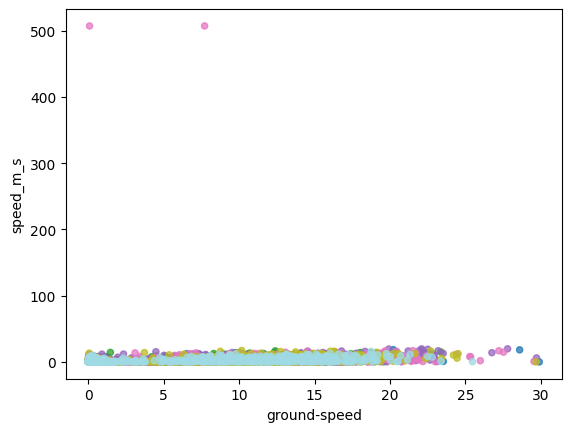

In [25]:
merged_df = pd.merge(traj_df, df, left_on='point_id', right_on='point_id_start', how='inner')
merged_df[['point_id', 'timestamp', 'speed_m_s', 'speed_m_s_next','ground-speed']]
individual_ids= merged_df[INDIVIDUAL_COL].map(individual_id_to_int).values
outlier_mask = np.asarray(merged_df['algorithm-marked-outlier_x'].fillna(False), dtype=bool)
inlier_mask = ~outlier_mask
plt.scatter(merged_df['ground-speed'][inlier_mask], merged_df['speed_m_s'][inlier_mask],
                    c=individual_ids[inlier_mask], cmap=cmap_individuals, alpha=0.75, s=20)
if outlier_mask.any():
    plt.scatter(merged_df['ground-speed'][outlier_mask], merged_df['speed_m_s'][outlier_mask],
                        c=cmap_individuals(individual_ids[outlier_mask]), marker='X', s=120,
                        edgecolors='k', linewidths=0.8)
plt.xlabel('ground-speed')
plt.ylabel('speed_m_s')

In [30]:
merged_df.columns

Index(['event-id', 'visible', 'timestamp', 'location-long_x', 'location-lat_x',
       'algorithm-marked-outlier_x', 'data-decoding-software', 'eobs:activity',
       'eobs:activity-samples', 'eobs:battery-voltage',
       'eobs:fix-battery-voltage', 'eobs:horizontal-accuracy-estimate',
       'eobs:key-bin-checksum', 'eobs:speed-accuracy-estimate',
       'eobs:start-timestamp', 'eobs:status', 'eobs:temperature',
       'eobs:type-of-fix', 'eobs:used-time-to-get-fix', 'gps:dop',
       'gps:satellite-count', 'ground-speed', 'heading',
       'height-above-ellipsoid', 'import-marked-outlier_x',
       'manually-marked-outlier_x', 'sensor-type',
       'individual-taxon-canonical-name', 'tag-local-identifier',
       'individual-local-identifier', 'study-name', 'set', '--logical-name',
       'acceleration-raw-x', 'acceleration-raw-y', 'acceleration-raw-z',
       'battery-charge-percent', 'battery-charging-current',
       'external-temperature', 'gps:hdop', 'gps-time-to-fix',
       '

Text(0, 0.5, 'gps:hdop')

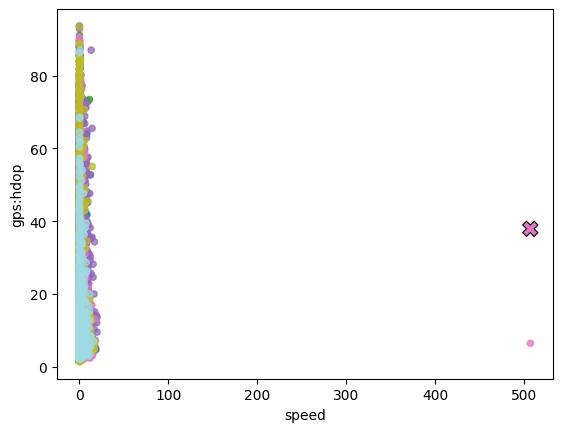

In [31]:
merged_df = pd.merge(traj_df, df, left_on='point_id', right_on='point_id_start', how='inner')
#merged_df[['point_id', 'timestamp', 'speed_m_s', 'speed_m_s_next','ground-speed']]
individual_ids= merged_df[INDIVIDUAL_COL].map(individual_id_to_int).values
outlier_mask = np.asarray(merged_df['any_outlier'].fillna(False), dtype=bool)
inlier_mask = ~outlier_mask
plt.scatter(merged_df['speed_m_s'][inlier_mask], merged_df['eobs:horizontal-accuracy-estimate'][inlier_mask],
                    c=individual_ids[inlier_mask], cmap=cmap_individuals, alpha=0.75, s=20)
if outlier_mask.any():
    plt.scatter(merged_df['speed_m_s'][outlier_mask], merged_df['eobs:horizontal-accuracy-estimate'][outlier_mask],
                        c=cmap_individuals(individual_ids[outlier_mask]), marker='X', s=120,
                        edgecolors='k', linewidths=0.8)
plt.xlabel('speed')
plt.ylabel('gps:hdop')

In [32]:
merged_df.columns

Index(['Unnamed: 0', 'event-id', 'visible', 'timestamp', 'location-long_x',
       'location-lat_x', 'algorithm-marked-outlier_x', 'gps:hdop',
       'gps:satellite-count', 'gps-time-to-fix', 'gps:vdop', 'ground-speed',
       'heading', 'height-above-ellipsoid', 'height-raw',
       'import-marked-outlier_x', 'location-error-text',
       'manually-marked-outlier_x', 'mw:show-in-kml',
       'raptor-workshop:migration-state', 'vertical-error-numerical',
       'sensor-type', 'individual-taxon-canonical-name',
       'tag-local-identifier', 'individual-local-identifier', 'study-name',
       'split-time', 'set', 'point-id', 'point_id', 'point_id_start',
       'step_length_m', 'step_dt_s', 'speed_m_s', 'turn_angle_rad',
       'step_length_m_next', 'step_dt_s_next', 'speed_m_s_next',
       'turn_angle_rad_next', 'any_outlier', 'individual',
       'algorithm-marked-outlier_y', 'import-marked-outlier_y',
       'manually-marked-outlier_y', 'location-long_y', 'location-lat_y'],
      dt

Text(0, 0.5, 'gps:vdop')

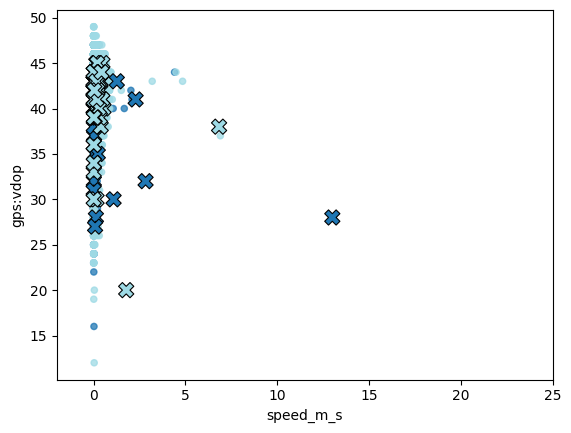

In [ ]:
merged_df = pd.merge(traj_df, df, left_on='point_id', right_on='point_id_start', how='inner')
#merged_df[['point_id', 'timestamp', 'speed_m_s', 'speed_m_s_next','ground-speed']]
individual_ids= merged_df[INDIVIDUAL_COL].map(individual_id_to_int).values
outlier_mask = np.asarray(merged_df.any_outlier, dtype=bool)
inlier_mask = ~outlier_mask
plt.scatter(merged_df['speed_m_s'][inlier_mask], merged_df['gps:maximum-signal-strength'][inlier_mask],
                    c=individual_ids[inlier_mask], cmap=cmap_individuals, alpha=0.75, s=20)
if outlier_mask.any():
    plt.scatter(merged_df['speed_m_s'][outlier_mask], merged_df['gps:maximum-signal-strength'][outlier_mask],
                        c=cmap_individuals(individual_ids[outlier_mask]), marker='X', s=120,
                        edgecolors='k', linewidths=0.8)
plt.xlim(-2,25)
plt.xlabel('speed_m_s')
plt.ylabel('gps:maximum-signal-strength')

In [34]:
merged_df[merged_df['any_outlier']].describe()

,event-id,timestamp,location-long_x,location-lat_x,data-decoding-software,eobs:activity,eobs:activity-samples,eobs:battery-voltage,eobs:fix-battery-voltage,eobs:horizontal-accuracy-estimate,...,step_length_m,step_dt_s,speed_m_s,turn_angle_rad,step_length_m_next,step_dt_s_next,speed_m_s_next,turn_angle_rad_next,location-long_y,location-lat_y
count,8.679000e+03,8679,8679.000000,8679.000000,0.0,4326.000000,4326.000000,8679.000000,1.0,1.00,...,8.679000e+03,8679.000000,8679.000000,8679.000000,8.679000e+03,8679.000000,8679.000000,8679.000000,8679.000000,8679.000000
mean,3.562018e+09,2017-05-07 16:59:27.126166784,0.717532,42.353382,NaN,15.147943,62.973417,3977.716903,3970.0,37.89,...,1.501258e+03,3610.697998,0.415950,-0.009820,1.626386e+03,3633.754639,0.450598,-0.005660,0.717532,42.353382
min,3.336453e+08,2014-06-18 15:59:47,-7.904006,33.750409,NaN,4.000000,11.000000,3700.000000,3970.0,37.89,...,9.212125e-02,2443.000000,0.000026,-3.140509,9.212125e-02,2215.000000,0.000026,-3.140465,-7.904006,33.750409
25%,2.008267e+09,2016-10-17 16:30:06.500000,-5.707726,37.423110,NaN,9.000000,42.000000,3922.000000,3970.0,37.89,...,1.198998e+01,3599.000000,0.003329,-1.746629,1.601360e+01,3599.000000,0.004443,-1.688016,-5.707726,37.423110
50%,3.241539e+09,2017-06-09 08:00:06,-1.374266,41.537619,NaN,13.000000,70.000000,3995.000000,3970.0,37.89,...,7.647544e+01,3600.000000,0.021230,-0.017801,9.698882e+01,3600.000000,0.026848,0.016466,-1.374266,41.537619
75%,4.916910e+09,2018-01-29 09:30:15,8.372577,48.641788,NaN,18.000000,84.000000,4047.000000,3970.0,37.89,...,4.615479e+02,3601.000000,0.128506,1.735416,5.940066e+02,3601.000000,0.164928,1.673131,8.372577,48.641788
max,1.196895e+10,2019-08-14 10:00:06,12.174815,53.466398,NaN,158.000000,84.000000,4072.000000,3970.0,37.89,...,1.825532e+06,58968.000000,507.092346,3.141426,1.825224e+06,21617.000000,507.147552,3.141426,12.174815,53.466398
std,2.192778e+09,NaN,6.366447,5.175409,NaN,11.648308,21.013917,75.745586,NaN,NaN,...,2.006040e+04,621.093018,5.570304,1.940173,2.006482e+04,706.843994,5.573088,1.909292,6.366447,5.175409


Text(0, 0.5, 'gps:satellite-count')

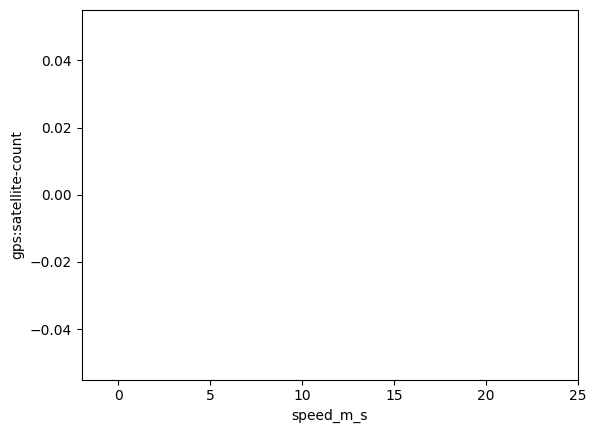

In [32]:
merged_df = pd.merge(traj_df, df, left_on='point_id', right_on='point_id_start', how='inner')
individual_ids= merged_df[INDIVIDUAL_COL].map(individual_id_to_int).values
outlier_mask = np.asarray(merged_df.any_outlier, dtype=bool)
inlier_mask = ~outlier_mask
plt.scatter(merged_df['speed_m_s'][inlier_mask], merged_df['gps:satellite-count'][inlier_mask],
                    c=individual_ids[inlier_mask], cmap=cmap_individuals, alpha=0.75, s=20)
if outlier_mask.any():
    plt.scatter(merged_df['speed_m_s'][outlier_mask], merged_df['gps:satellite-count'][outlier_mask],
                        c=cmap_individuals(individual_ids[outlier_mask]), marker='X', s=120,
                        edgecolors='k', linewidths=0.8)
plt.xlabel('speed_m_s')
plt.xlim(-2,25)

plt.ylabel('gps:satellite-count')

## Outlier feature analysis — `sample_merged.csv` (Red Fox)

The red fox dataset includes GPS quality columns (`gps:hdop`, `gps:satellite-count`, `height-above-msl`) not available in atlas_bats.
We use a Random Forest + Cohen's d to find which features best separate outlier from normal points.

In [27]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")

fox = merged_df#pd.read_csv("sample_merged.csv")
fox["outlier"] = fox["any_outlier"].fillna(False).astype(bool)

FEATURE_COLS = [
    "gps:hdop", "gps:satellite-count", #"height-above-msl",
    "speed_m_s", "step_length_m", "step_dt_s",
    #'gps:vdop',
    #  "speed_m_s_next",
    #'ground-speed'
    "gps:maximum-signal-strength", #"external-temperature", 
    "turn_angle_rad",
]
FEATURE_LABELS = {
    "gps:hdop":                    "GPS HDOP",
    "gps:satellite-count":         "Satellite Count",
    "gps:maximum-signal-strength": "GPS Signal Strength",
    #'gps:vdop':                    "GPS VDOP",
    'ground-speed':                 "Ground Speed (m/s)",
    #"height-above-msl":            "Height Above MSL (m)",
    "speed_m_s":                   "Speed (m/s)",
   # 'speed_m_s_next':              "Next Speed (m/s)",
    "step_length_m":               "Step Length (m)",
    "step_dt_s":                   "Step Duration (s)",
   # "gps:maximum-signal-strength": "GPS Signal Strength",
    #"external-temperature":        "External Temp (°C)",
    "turn_angle_rad":              "Turn Angle (rad)",
}
PALETTE = {"normal": "#4C9BE8", "outlier": "#E8614C"}

fox_feat = fox[FEATURE_COLS + ["outlier"]].dropna()
X = fox_feat[FEATURE_COLS]
y = fox_feat["outlier"].astype(int)

rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
rf.fit(X, y)
importances = pd.Series(rf.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)

normal_  = fox[~fox["outlier"]]
outlier_ = fox[fox["outlier"]]

cohens = {}
for col in FEATURE_COLS:
    o, n = outlier_[col].dropna(), normal_[col].dropna()
    pooled = np.sqrt((o.std() ** 2 + n.std() ** 2) / 2)
    cohens[col] = (o.mean() - n.mean()) / pooled if pooled > 0 else 0.0

print(f"Total points: {len(fox):,}  |  Outliers: {fox['outlier'].sum():,}  ({fox['outlier'].mean():.1%})")
print("\nRandom Forest importances:")
print(importances.round(3).to_string())
print("\nCohen's d:")
for k, v in sorted(cohens.items(), key=lambda x: abs(x[1]), reverse=True):
    print(f"  {k:35s} {v:+.3f}")

Total points: 34,326  |  Outliers: 117  (0.3%)

Random Forest importances:
gps:hdop                       0.411
gps:satellite-count            0.314
step_length_m                  0.086
speed_m_s                      0.073
turn_angle_rad                 0.048
step_dt_s                      0.038
gps:maximum-signal-strength    0.030

Cohen's d:
  gps:satellite-count                 -3.023
  gps:hdop                            +2.189
  gps:maximum-signal-strength         -0.450
  step_length_m                       +0.157
  speed_m_s                           +0.152
  turn_angle_rad                      +0.115
  step_dt_s                           -0.013


### Fig 1 — Feature Importance (RF) and Cohen's d

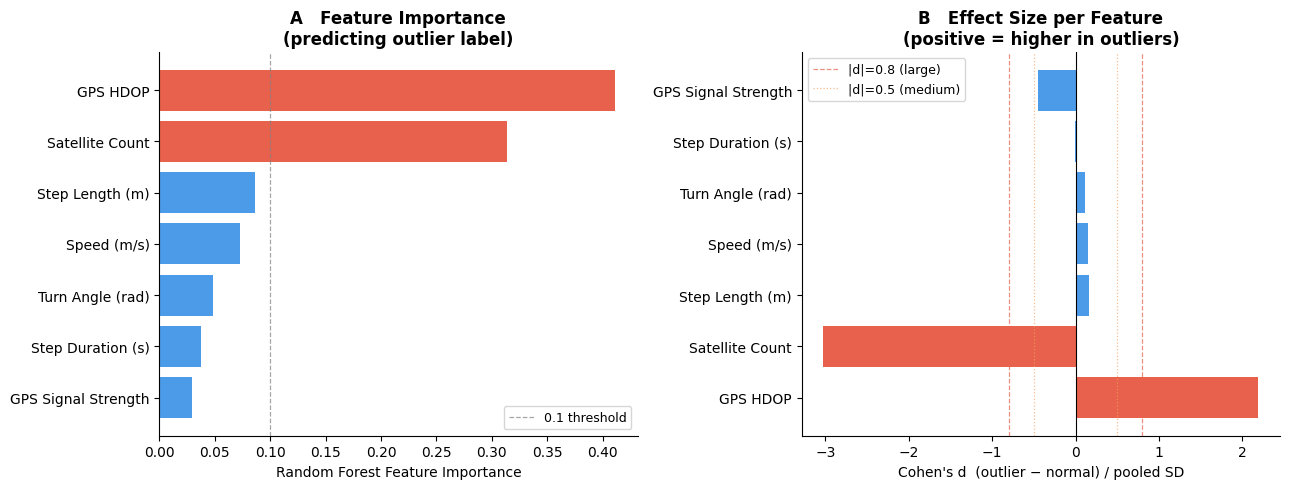

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel A: RF importance
ax = axes[0]
imp_sorted = importances.sort_values()
colors_imp = ["#E8614C" if v >= 0.1 else "#4C9BE8" for v in imp_sorted.values]
ax.barh([FEATURE_LABELS[f] for f in imp_sorted.index], imp_sorted.values, color=colors_imp)
ax.axvline(0.1, color="gray", linestyle="--", lw=0.9, alpha=0.7, label="0.1 threshold")
ax.set_xlabel("Random Forest Feature Importance")
ax.set_title("A   Feature Importance\n(predicting outlier label)", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=9)

# Panel B: Cohen's d
ax = axes[1]
cohens_s = pd.Series(cohens).reindex(importances.index)
colors_d = [
    "#E8614C" if abs(v) >= 0.8 else ("#F4A261" if abs(v) >= 0.5 else "#4C9BE8")
    for v in cohens_s.values
]
ax.barh([FEATURE_LABELS[f] for f in cohens_s.index], cohens_s.values, color=colors_d)
ax.axvline(0, color="black", lw=0.8)
ax.axvline( 0.8, color="#E8614C", linestyle="--", lw=0.9, alpha=0.7, label="|d|=0.8 (large)")
ax.axvline(-0.8, color="#E8614C", linestyle="--", lw=0.9, alpha=0.7)
ax.axvline( 0.5, color="#F4A261", linestyle=":",  lw=0.9, alpha=0.7, label="|d|=0.5 (medium)")
ax.axvline(-0.5, color="#F4A261", linestyle=":",  lw=0.9, alpha=0.7)
ax.set_xlabel("Cohen's d  (outlier − normal) / pooled SD")
ax.set_title("B   Effect Size per Feature\n(positive = higher in outliers)", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "vulture_fig1_importance_cohens_d.png", dpi=150, bbox_inches="tight")
plt.show()

### Fig 2 — Feature distributions: Normal vs Outlier

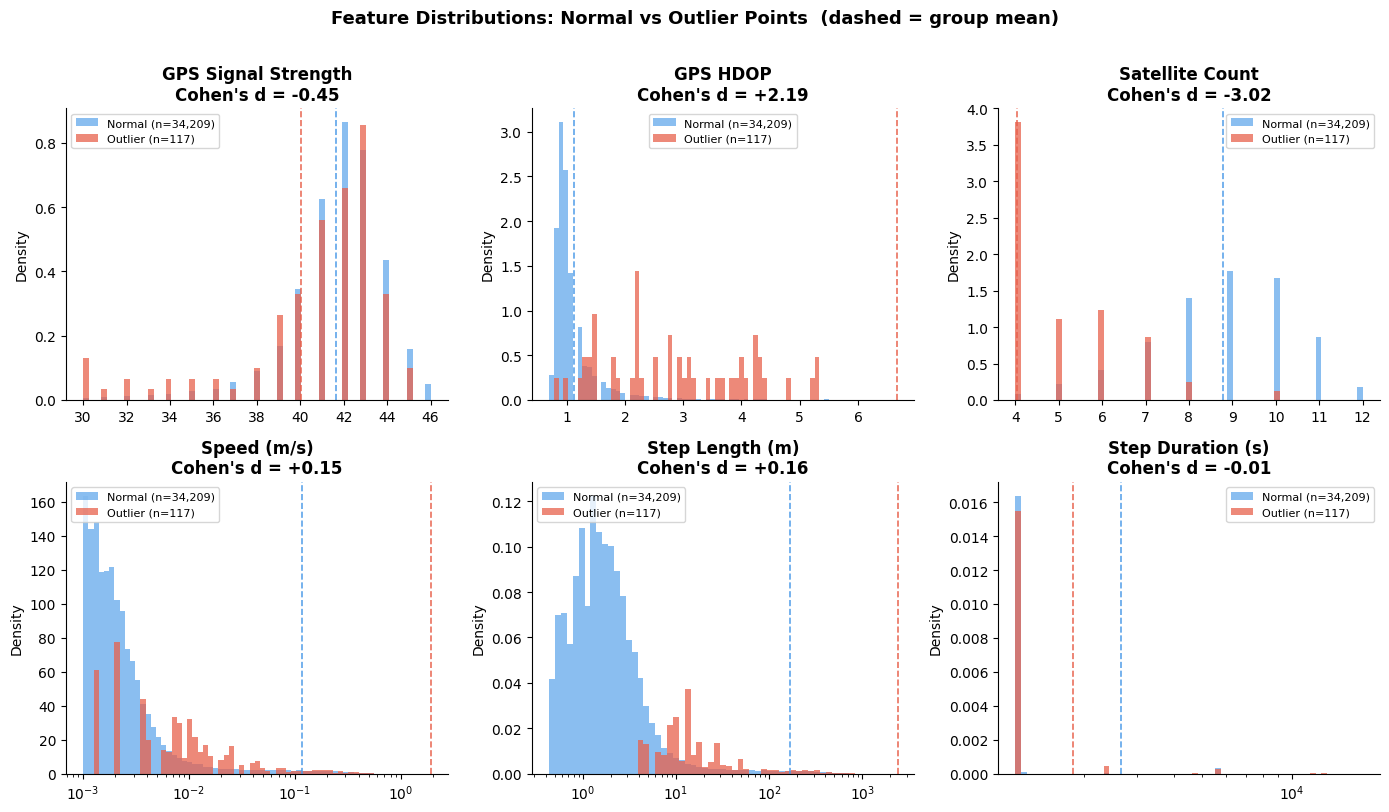

In [30]:
top_feats = ['gps:maximum-signal-strength',
             "gps:hdop", "gps:satellite-count", #"height-above-msl",
             "speed_m_s", "step_length_m", "step_dt_s"]
log_feats = {"speed_m_s", "step_length_m", "step_dt_s",# "height-above-msl"
             }

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for ax, feat in zip(axes, top_feats):
    v_n = normal_[feat].dropna()
    v_o = outlier_[feat].dropna()
    use_log = feat in log_feats and (v_n > 0).any() and (v_o > 0).any()

    all_v = pd.concat([v_n, v_o])
    if use_log:
        lo = max(all_v[all_v > 0].quantile(0.01), 1e-3)
        hi = all_v.quantile(0.999)
        bins = np.logspace(np.log10(lo), np.log10(hi), 60)
    else:
        bins = np.linspace(all_v.quantile(0.005), all_v.quantile(0.995), 60)

    ax.hist(v_n, bins=bins, density=True, alpha=0.65, color=PALETTE["normal"],
            label=f"Normal (n={len(v_n):,})")
    ax.hist(v_o, bins=bins, density=True, alpha=0.75, color=PALETTE["outlier"],
            label=f"Outlier (n={len(v_o):,})")
    if use_log:
        ax.set_xscale("log")

    ax.axvline(v_n.mean(), color=PALETTE["normal"],  linestyle="--", lw=1.2, alpha=0.9)
    ax.axvline(v_o.mean(), color=PALETTE["outlier"], linestyle="--", lw=1.2, alpha=0.9)
    ax.set_title(f"{FEATURE_LABELS[feat]}\nCohen's d = {cohens[feat]:+.2f}", fontweight="bold")
    ax.set_ylabel("Density")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=8)

plt.suptitle("Feature Distributions: Normal vs Outlier Points  (dashed = group mean)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "vulture_fig2_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

### Fig 3 — GPS quality space: outliers cluster in high-HDOP / low-satellite / high-altitude corner

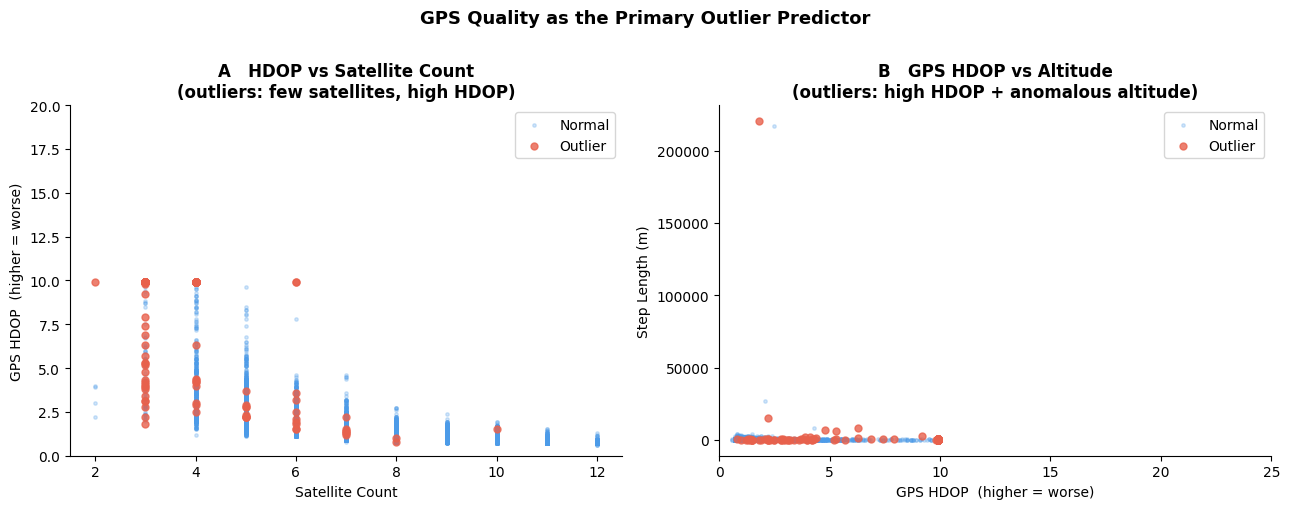

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

scatter_kwargs = [
    ("Normal",  ~fox["outlier"], PALETTE["normal"],  0.25, 6,  1),
    ("Outlier",  fox["outlier"], PALETTE["outlier"], 0.80, 25, 2),
]

# Panel A: HDOP vs satellite count
ax = axes[0]
for label, mask, color, alpha, size, zorder in scatter_kwargs:
    sub = fox[mask].dropna(subset=["gps:hdop", "gps:satellite-count"])
    ax.scatter(sub["gps:satellite-count"], sub["gps:hdop"],
               c=color, alpha=alpha, s=size, label=label, zorder=zorder)
ax.set_xlabel("Satellite Count")
ax.set_ylabel("GPS HDOP  (higher = worse)")
ax.set_ylim(0, 20)
ax.set_title("A   HDOP vs Satellite Count\n(outliers: few satellites, high HDOP)", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend()

# Panel B: HDOP vs altitude
ax = axes[1]
for label, mask, color, alpha, size, zorder in scatter_kwargs:
    sub = fox[mask].dropna(subset=["gps:hdop", "step_length_m"])
    ax.scatter(sub["gps:hdop"], sub["step_length_m"],
               c=color, alpha=alpha, s=size, label=label, zorder=zorder)
ax.set_xlabel("GPS HDOP  (higher = worse)")
ax.set_ylabel("Step Length (m)")
ax.set_xlim(0, 25)
ax.set_title("B   GPS HDOP vs Altitude\n(outliers: high HDOP + anomalous altitude)", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend()

plt.suptitle("GPS Quality as the Primary Outlier Predictor", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "vulture_fig3_gps_quality.png", dpi=150, bbox_inches="tight")
plt.show()

### Fig 4 — % difference in mean: outlier vs normal (movement features have extreme shifts)

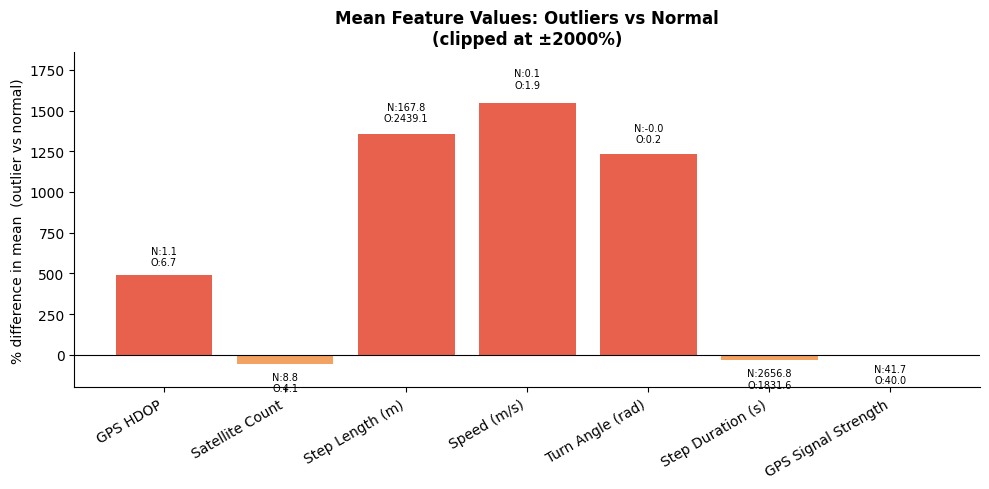

In [32]:
pct_diff = {}
for feat in FEATURE_COLS:
    n_mean = normal_[feat].mean()
    o_mean = outlier_[feat].mean()
    pct_diff[feat] = (o_mean - n_mean) / abs(n_mean) * 100 if n_mean != 0 else 0.0

pct_s = pd.Series(pct_diff).reindex(importances.index)

fig, ax = plt.subplots(figsize=(10, 5))
colors_p = ["#E8614C" if abs(v) > 100 else "#F4A261" if abs(v) > 20 else "#4C9BE8"
            for v in pct_s.values]
bars = ax.bar([FEATURE_LABELS[f] for f in pct_s.index], pct_s.values, color=colors_p)
ax.axhline(0, color="black", lw=0.8)

# Annotate with raw means
for i, feat in enumerate(pct_s.index):
    pct = pct_s[feat]
    n_m = normal_[feat].mean()
    o_m = outlier_[feat].mean()
    offset = max(50, abs(pct) * 0.05) * np.sign(pct) if pct != 0 else 30
    ax.text(i, pct + offset, f"N:{n_m:.1f}\nO:{o_m:.1f}",
            ha="center", va="bottom" if pct >= 0 else "top", fontsize=7)

ax.set_ylabel("% difference in mean  (outlier vs normal)")
ax.set_title("Mean Feature Values: Outliers vs Normal\n(clipped at ±2000%)", fontweight="bold")
ax.set_xticklabels([FEATURE_LABELS[f] for f in pct_s.index], rotation=30, ha="right")
ax.set_ylim(min(-200, pct_s.min() * 1.15), min(2200, pct_s.max() * 1.2))
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(FIG_DIR / "vulture_fig4_mean_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [24]:
X

,speed_m_s,step_length_m,step_dt_s,gps:hdop,gps:satellite-count
11444,0.006333,2.754247e+01,4349.0,1.6,5.0
11445,0.209743,2.584034e+02,1232.0,1.5,5.0
11446,0.053036,6.587031e+01,1242.0,1.6,5.0
11447,0.021495,2.695462e+01,1254.0,1.3,6.0
11448,0.008240,1.105846e+01,1342.0,1.3,6.0
...,...,...,...,...,...
124825,0.001120,1.293870e+01,11549.0,1.2,8.0
124826,0.008042,5.708915e+01,7099.0,1.3,6.0
124827,0.115507,8.397387e+02,7270.0,4.8,4.0
124828,1234.162598,8.826731e+06,7152.0,0.0,0.0


In [17]:
X.mean()

speed_m_s                 41.373409
step_length_m          57718.597656
step_dt_s                950.039307
gps:hdop                   1.338754
gps:satellite-count        7.539984
dtype: float64

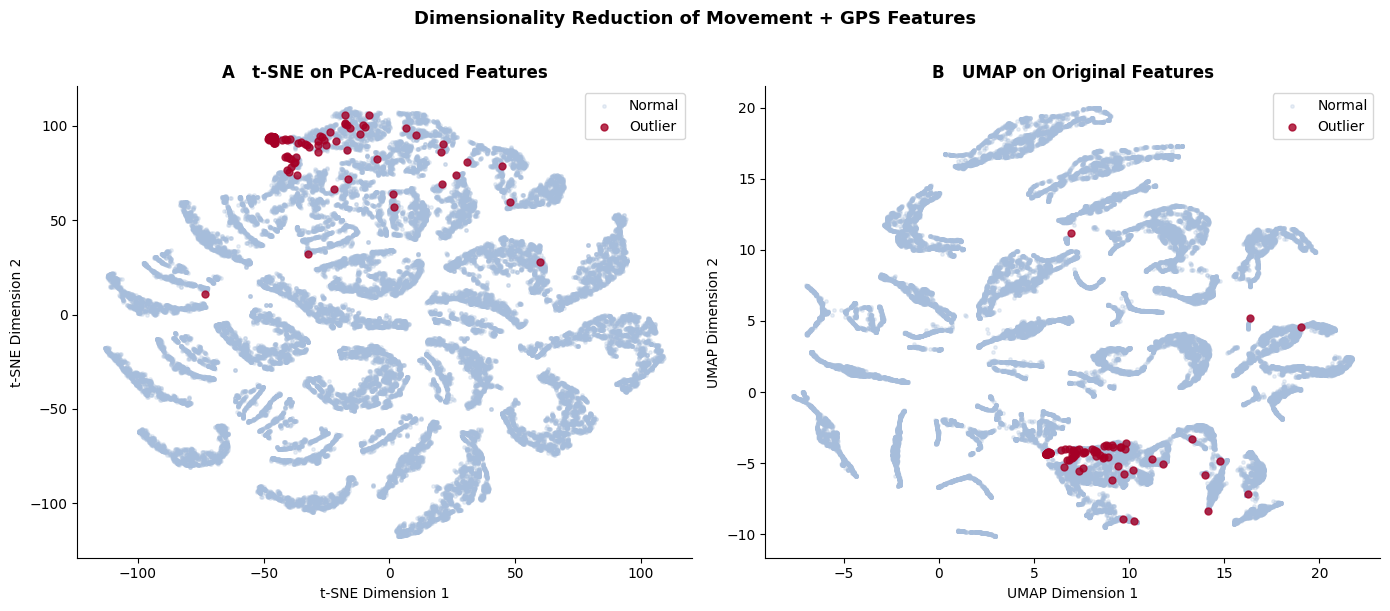

In [33]:
#features should be movement features and gps features. let's do dim reduction on these and see what comes up:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap
feat_cols = ["speed_m_s", "step_length_m", "turn_angle_rad", "gps:hdop", "gps:satellite-count",'gps:maximum-signal-strength']
X = merged_df[feat_cols].dropna()
# center and scale each features separately for better dim reduction
X = (X - X.mean()) / X.std()
y = merged_df.loc[X.index, "any_outlier"].astype(int)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
tsne = TSNE(n_components=2, random_state=42, perplexity=50)
X_tsne = tsne.fit_transform(X)  
umap_reducer = umap.UMAP(n_components=2, random_state=42)
X_umap = umap_reducer.fit_transform(X)
# Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#a6bddb', '#a50026']
scatter_kwargs = [
    ("Normal",  y == 0, colors[0],  0.25, 6,  1),
    ("Outlier", y == 1, colors[1], 0.80, 25, 2),
]
# Panel A: t-SNE
ax = axes[0]
for label, mask, color, alpha, size, zorder in scatter_kwargs:
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
               c=color, alpha=alpha, s=size, label=label, zorder=zorder)
ax.set_title("A   t-SNE on PCA-reduced Features", fontweight="bold")
ax.set_xlabel("t-SNE Dimension 1")
ax.set_ylabel("t-SNE Dimension 2")
ax.spines[["top", "right"]].set_visible(False)
ax.legend() 
# Panel B: UMAP
ax = axes[1]
for label, mask, color, alpha, size, zorder in scatter_kwargs:
    ax.scatter(X_umap[mask, 0], X_umap[mask, 1],
               c=color, alpha=alpha, s=size, label=label, zorder=zorder)
ax.set_title("B   UMAP on Original Features", fontweight="bold")
ax.set_xlabel("UMAP Dimension 1")
ax.set_ylabel("UMAP Dimension 2")
ax.spines[["top", "right"]].set_visible(False)
ax.legend()
plt.suptitle("Dimensionality Reduction of Movement + GPS Features", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()

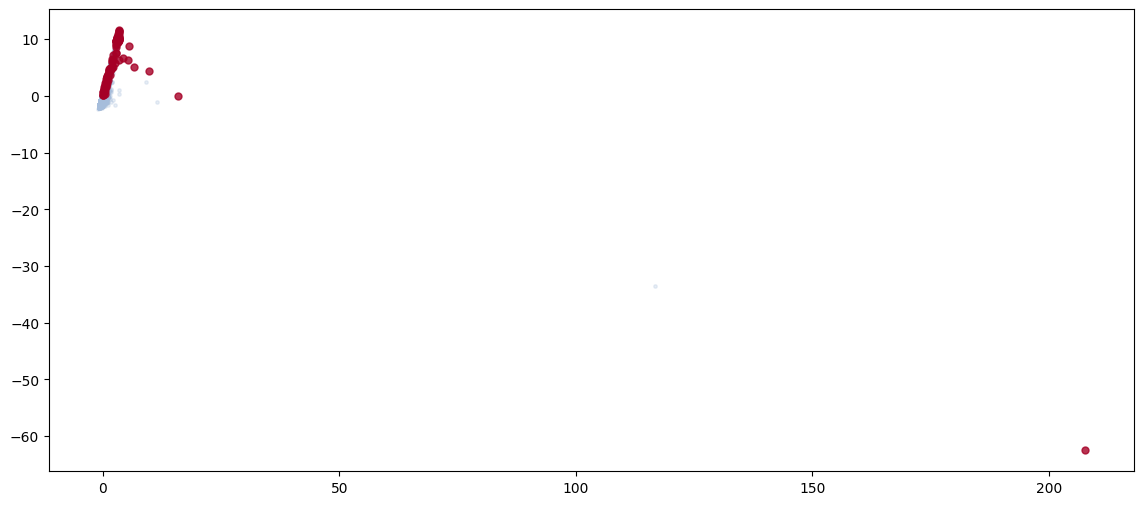

In [34]:
fig, ax = plt.subplots(1, 1, figsize=(14, 6))
colors = ['#a6bddb', '#a50026']
scatter_kwargs = [
    ("Normal",  y == 0, colors[0],  0.25, 6,  1),
    ("Outlier", y == 1, colors[1], 0.80, 25, 2),
]
# Panel A: t-SNE

for label, mask, color, alpha, size, zorder in scatter_kwargs:
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=color, alpha=alpha, s=size, label=label, zorder=zorder)